# MTG Analysis Visualization

This notebook downloads the current Scryfall default-card dataset, analyzes expansion-set card prices by color identity, release year, set, and color combination, and displays interactive Plotly and Seaborn visualizations.

Run the notebook from the repository root after installing the dependencies with `uv sync`. The first code cell requires internet access and writes the downloaded data to `cards.json`.

In [1]:
import requests

url = "https://data.scryfall.io/default-cards/default-cards-20260414090745.json"

response = requests.get(url)
with open("cards.json", "wb") as f:
    f.write(response.content)

In [2]:
import pandas as pd

df = pd.read_json("cards.json")

In [3]:
full_data = pd.DataFrame({
    "products.name": df["name"],
    "released_at": df["released_at"],
    "mana_cost": df["mana_cost"],
    "cmc": df["cmc"],
    "type_line": df["type_line"],
    "oracle_text": df["oracle_text"],
    "set_name": df["set_name"],
    "set_type": df["set_type"],
    "image_uris": df["image_uris"]
})

full_data["priceGuides.avg"] = df["prices"].apply(lambda x: x.get("usd") if isinstance(x, dict) else None)
full_data["priceGuides.avg-foil"] = df["prices"].apply(lambda x: x.get("usd_foil") if isinstance(x, dict) else None)
full_data["image_uris"] = full_data["image_uris"].str["normal"]

full_data["priceGuides.avg"] = pd.to_numeric(full_data["priceGuides.avg"],errors="coerce")
full_data = full_data[full_data["set_type"] == "expansion"]
full_data.head()

,products.name,released_at,mana_cost,cmc,type_line,oracle_text,set_name,set_type,image_uris,priceGuides.avg,priceGuides.avg-foil
0,Forest,2024-08-02,,0.0,Basic Land — Forest,({T}: Add {G}.),Bloomburrow,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.32,0.44
1,Fury Sliver,2006-10-06,{5}{R},6.0,Creature — Sliver,All Sliver creatures have double strike.,Time Spiral,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.53,2.85
2,Kor Outfitter,2009-10-02,{W}{W},2.0,Creature — Kor Soldier,"When this creature enters, you may attach targ...",Zendikar,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.18,1.77
4,Siren Lookout,2017-09-29,{2}{U},3.0,Creature — Siren Pirate,"Flying\nWhen this creature enters, it explores...",Ixalan,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.10,0.23
8,Obyra's Attendants // Desperate Parry,2023-09-08,{4}{U} // {1}{U},5.0,Creature — Faerie Wizard // Instant — Adventure,NaN,Wilds of Eldraine,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.09,0.10


In [4]:
import numpy as np

color_map = {
    "W": "White",
    "U": "Blue",
    "B": "Black",
    "R": "Red",
    "G": "Green"
}

combo_map = {
    frozenset(["W","U"]): "Azorius",
    frozenset(["U","B"]): "Dimir",
    frozenset(["B","R"]): "Rakdos",
    frozenset(["R","G"]): "Gruul",
    frozenset(["G","W"]): "Selesnya",
    
    frozenset(["W","B"]): "Orzhov",
    frozenset(["U","R"]): "Izzet",
    frozenset(["B","G"]): "Golgari",
    frozenset(["R","W"]): "Boros",
    frozenset(["G","U"]): "Simic",

    frozenset(["W","U","G"]): "Bant",
    frozenset(["W","U","B"]): "Esper",
    frozenset(["U","B","R"]): "Grixis",
    frozenset(["B","R","G"]): "Jund",
    frozenset(["W","R","G"]): "Naya",
    frozenset(["W","B","G"]): "Abzan",
    frozenset(["U","R","W"]): "Jeskai",
    frozenset(["U","B","G"]): "Sultai",
    frozenset(["W","B","R"]): "Mardu",
    frozenset(["U","R","G"]): "Temur",

    frozenset(["U","B","R","G"]): "Glint-Eye",
    frozenset(["B","R","G","W"]): "Dune-Brood",
    frozenset(["R","G","W","U"]): "Ink-Treader",
    frozenset(["G","W","U","B"]): "Witch-Maw",
    frozenset(["W","U","B","R"]): "Yore-Tiller",

    frozenset(["W","U","B","R","G"]): "Rainbow"
}

def get_color_info(mana_cost):
    if pd.isna(mana_cost):
        return np.nan, []

    mtg_order = ["W", "U", "B", "R", "G"]

    colors = sorted(
        set([c for c in mana_cost if c in "WUBRG"]),
        key=lambda x: mtg_order.index(x)
    )

    # No colors
    if len(colors) == 0:
        return "Colorless", []

    # Mono color
    if len(colors) == 1:
        return f"mono-{color_map[colors[0]]}", colors

    # Multi-color
    key = frozenset(colors)
    name = combo_map.get(key, "".join(colors))

    return name, colors

full_data[["color_identity", "colors"]] = full_data["mana_cost"].apply(lambda x: pd.Series(get_color_info(x)))
full_data.head()

,products.name,released_at,mana_cost,cmc,type_line,oracle_text,set_name,set_type,image_uris,priceGuides.avg,priceGuides.avg-foil,color_identity,colors
0,Forest,2024-08-02,,0.0,Basic Land — Forest,({T}: Add {G}.),Bloomburrow,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.32,0.44,Colorless,[]
1,Fury Sliver,2006-10-06,{5}{R},6.0,Creature — Sliver,All Sliver creatures have double strike.,Time Spiral,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.53,2.85,mono-Red,[R]
2,Kor Outfitter,2009-10-02,{W}{W},2.0,Creature — Kor Soldier,"When this creature enters, you may attach targ...",Zendikar,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.18,1.77,mono-White,[W]
4,Siren Lookout,2017-09-29,{2}{U},3.0,Creature — Siren Pirate,"Flying\nWhen this creature enters, it explores...",Ixalan,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.10,0.23,mono-Blue,[U]
8,Obyra's Attendants // Desperate Parry,2023-09-08,{4}{U} // {1}{U},5.0,Creature — Faerie Wizard // Instant — Adventure,NaN,Wilds of Eldraine,expansion,https://cards.scryfall.io/normal/front/0/0/000...,0.09,0.10,mono-Blue,[U]


In [5]:
mono_data = full_data[
    full_data["color_identity"].str.startswith("mono-", na=False) |
    (full_data["color_identity"] == "Colorless")
]

import plotly.express as px

#Color map generated with ChatGPT on 3/30/2026
color_map_plotly = {
    "mono-White": "#FFD84D",   # off-white (avoids pink tint)
    "mono-Blue": "#1E90FF",    # clear blue (more reliable than dark navy)
    "mono-Black": "#2B2B2B",   # dark gray-black (visible on screen)
    "mono-Red": "#E74C3C",     # strong red
    "mono-Green": "#2ECC71",   # green
    "Colorless": "#A0A0A0"     # gray
}

fig = px.scatter(
    mono_data,
    x="released_at",
    y="priceGuides.avg",
    color="color_identity",
    color_discrete_map=color_map_plotly,
    title="Card Prices Over Time (Mono-Colored)",
    labels={
        "released_at": "Release Date",
        "priceGuides.avg": "Average Price",
        "color_identity": "Color Identity"
    }
)

colors = mono_data["color_identity"].dropna().unique()
buttons = []
buttons.append(dict(
    label="All",
    method="update",
    args=[{"visible": [True] * len(fig.data)}]
))
for i, c in enumerate(colors):
    visible = [False] * len(fig.data)
    visible[i] = True
    buttons.append(dict(
        label=c,
        method="update",
        args=[{"visible": visible}]
    ))

fig.update_layout(
    updatemenus=[dict(
        buttons=buttons,
        direction="down"
    )]
)

fig.update_yaxes(type="log")
fig.update_traces(marker=dict(size=5, opacity=0.6))
fig.show()

color_avg = mono_data.groupby("color_identity")["priceGuides.avg"].mean()
print(color_avg)

percentage = full_data["color_identity"].str.startswith("mono").mean() * 100
print(f"Percentage of cards that are mono-colored: {percentage}%")

color_identity
Colorless     7.487424
mono-Black    2.971055
mono-Blue     2.160321
mono-Green    2.380813
mono-Red      1.338986
mono-White    1.822627
Name: priceGuides.avg, dtype: float64
Percentage of cards that are mono-colored: 67.64620496113028%


In [6]:
full_data["released_at"] = pd.to_datetime(full_data["released_at"])
full_data["year"] = full_data["released_at"].dt.year
year_avg = (
    full_data
    .groupby("year")["priceGuides.avg"]
    .mean()
)
print(year_avg)

year
1993    141.769326
1994     31.998296
1995      1.338604
1996      3.793060
1997      3.890585
1998      9.818915
1999      3.818522
2000      1.460142
2001      1.416468
2002      2.367893
2003      1.848552
2004      2.239702
2005      1.318003
2006      1.214252
2007      1.703251
2008      1.730159
2009      1.319839
2010      1.801589
2011      1.255673
2012      0.801317
2013      0.671972
2014      0.731803
2015      0.416150
2016      0.464441
2017      0.579198
2018      0.690307
2019      1.226982
2020      1.991892
2021      1.181206
2022      1.443094
2023      1.916084
2024      2.089964
2025      1.995810
2026      4.377571
Name: priceGuides.avg, dtype: float64


In [7]:
counts = full_data["color_identity"].value_counts()
print(counts)

color_identity
Colorless      4991
mono-Black     4231
mono-White     4217
mono-Red       4193
mono-Green     4175
mono-Blue      4155
Selesnya        384
Boros           383
Dimir           371
Azorius         366
Orzhov          363
Golgari         361
Rakdos          357
Gruul           350
Simic           349
Izzet           343
Naya             87
Bant             78
Grixis           76
Jund             71
Esper            69
Sultai           63
Temur            57
Jeskai           56
Rainbow          51
Mardu            48
Abzan            45
Witch-Maw         5
Ink-Treader       4
Yore-Tiller       1
Glint-Eye         1
Dune-Brood        1
Name: count, dtype: int64


In [8]:
from itertools import combinations
import plotly.express as px

def is_subset(card_colors, combo):
    if not isinstance(card_colors, list):
        return False
    return set(card_colors).issubset(combo)

def generate_color_combos(max_colors=3):
    colors = ["W", "U", "B", "R", "G"]
    combos = []
    
    for r in range(1, max_colors + 1):
        combos.extend([set(c) for c in combinations(colors, r)])
    
    return combos

def compute_color_averages(df):
    combos = generate_color_combos(max_colors=3)
    results = []

    for combo in combos:
        subset = df[
            df["colors"].apply(lambda x: is_subset(x, combo))
        ]

        if len(subset) < 10:
            continue

        avg_price = subset["priceGuides.avg"].mean()

        results.append({
            "combo": "".join(sorted(combo)),
            "num_colors": len(combo),
            "avg_price": avg_price
        })

    return pd.DataFrame(results).sort_values("avg_price", ascending=True)

combo_data = compute_color_averages(full_data)


fig = px.bar(
    combo_data.sort_values("avg_price"),
    x="combo",
    y="avg_price",
    title="Color Combo Price Efficiency",
    labels={
        "combo": "Color Combination",
        "efficiency": "Efficiency (Cards per Dollar)"
    }
)
fig.update_layout(height=500)
fig.update_yaxes(range=[2.75,5.5])
fig.update_traces(text=combo_data["avg_price"].round(2), textposition="outside")
fig.show()

/home/holden/.venv/lib/python3.12/site-packages/seaborn/axisgrid.py:44: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set(**kwargs)


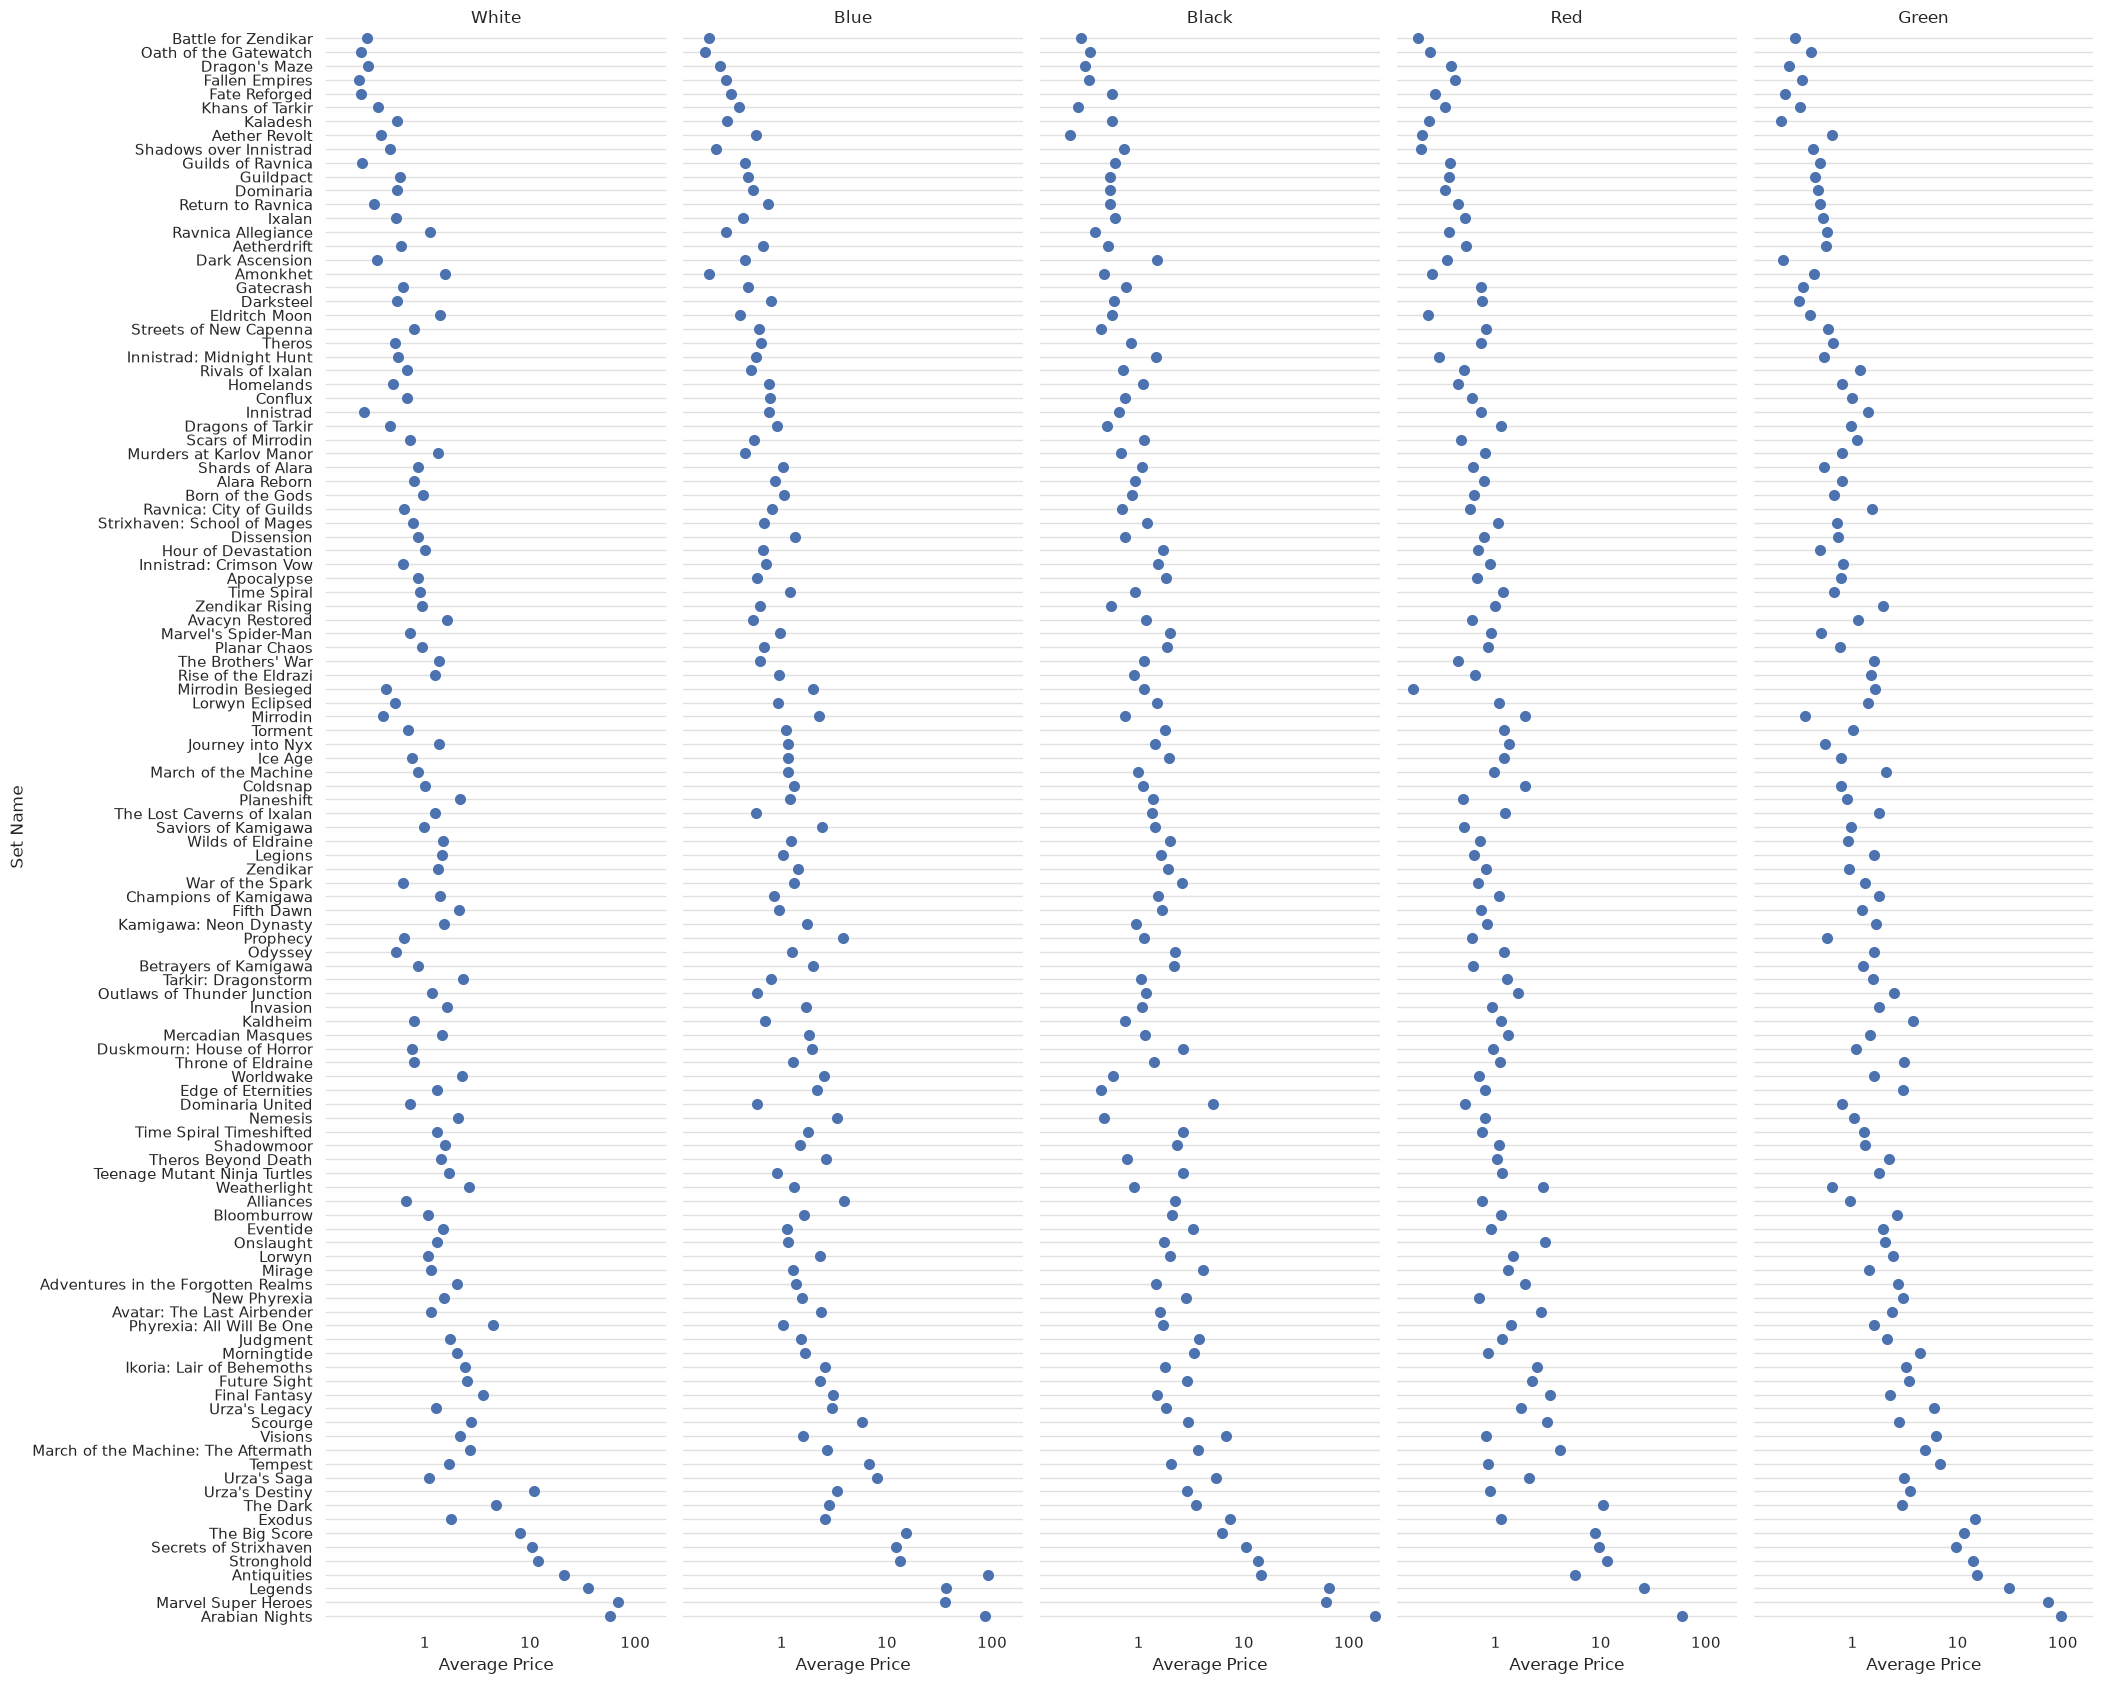

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker

expanded_data = full_data.explode("colors")
expanded_data = expanded_data[expanded_data["colors"].notna()] # Not including colorless cards
expanded_data = expanded_data[expanded_data["priceGuides.avg"] > 0]

plot_data = (
    expanded_data
    .groupby(["set_name", "colors"])["priceGuides.avg"]
    .mean()
    .reset_index()
)
color_map = {
    "W": "White",
    "U": "Blue",
    "B": "Black",
    "R": "Red",
    "G": "Green"
}
plot_data["colors"] = plot_data["colors"].map(color_map)

sns.set_theme(style="whitegrid")

g = sns.FacetGrid(
    plot_data,
    col="colors",
    col_order=["White", "Blue", "Black", "Red", "Green"],
    sharex=True,
    sharey=False,
    height=17,
    aspect=.25
)

g.set(xscale="log")
order = plot_data.groupby("set_name")["priceGuides.avg"].mean().sort_values(ascending=True).index

g.map_dataframe(
    sns.stripplot,
    x="priceGuides.avg",
    y="set_name",
    order=order,
    jitter=True,
    size=8
)

max_price = plot_data["priceGuides.avg"].max()
g.set(xlim=(0, max_price+20))

for ax in g.axes.flat:
    ax.grid(True, axis="y", linestyle="-", alpha=0.6)
    ax.grid(False, axis="x")

for i, ax in enumerate(g.axes.flat):
    if i != 0:
        ax.set_ylabel("")
        ax.set_yticklabels([])

for ax in g.axes.flat:
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f'))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

g.fig.tight_layout()
g.set_axis_labels("Average Price", "Set Name")
g.set_titles("{col_name}")
g.fig.subplots_adjust(wspace=0.05)
sns.despine(left=True, bottom=True)
plt.savefig('MTG_Set_Price.png')
plt.show()

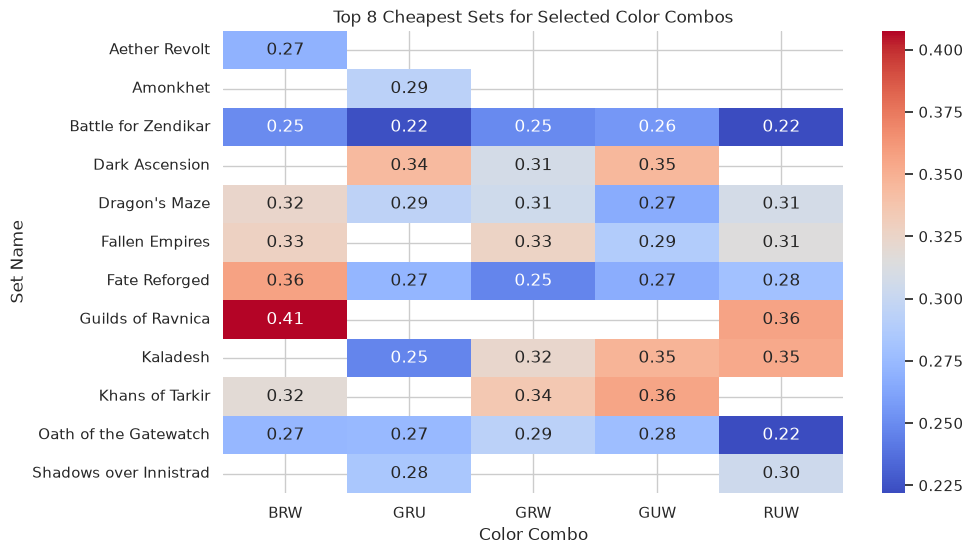

In [13]:
set_avg = (
    expanded_data
    .groupby("set_name")["priceGuides.avg"]
    .mean()
    .sort_values()
)
top20_sets = set_avg.head(20).index

target_combos = {
    "RUW": ["R", "U", "W"],
    "GRW": ["G", "R", "W"],
    "GRU": ["G", "R", "U"],
    "BRW": ["B", "R", "W"],
    "GUW": ["G", "U", "W"]
}

set_data = expanded_data[
    expanded_data["set_name"].isin(top20_sets)
]

results = []

for combo_name, combo_colors in target_combos.items():
    
    subset = set_data[
        set_data["colors"].isin(combo_colors)
    ]
    
    grouped = (
        subset
        .groupby("set_name")["priceGuides.avg"]
        .mean()
        .reset_index()
    )
    
    grouped["combo"] = combo_name
    results.append(grouped)

combo_set_data = pd.concat(results)

top8_per_combo = (
    combo_set_data
    .sort_values(["combo", "priceGuides.avg"])
    .groupby("combo")
    .head(8)
)

pivot = top8_per_combo.pivot(
    index="set_name",
    columns="combo",
    values="priceGuides.avg"
)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Top 8 Cheapest Sets for Selected Color Combos")
plt.xlabel("Color Combo")
plt.ylabel("Set Name")
plt.savefig('MTG_Combos_Best_Sets.png', bbox_inches='tight')

# Using all and only the sets listed with the exception of Khans of Tarkir since it is such a Jeskai heavy set
plt.show()